# 01 — Exploratory data analysis: CP-AnemiC

Input: `outputs/features_cp_anemic.csv` (one row per child, produced by `scripts.extract_features`) plus
`outputs/cleaning_log.csv`. Every figure is saved to `outputs/figures/eda/`.

**Leakage note.** This notebook is descriptive and uses the whole cleaned dataset. Nothing here (feature rankings,
PCA, correlations) may be used to *choose* features or thresholds for the model — those choices must be made
inside the training folds of the grouped CV.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "src")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

import config
from netra.features import prune_redundant
from netra.labels import _BANDS

FIG_DIR = config.OUT_DIR / "figures" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

NORMAL, ANAEMIC = "#2a78d6", "#eb6834"
PALETTE = {"Normal": NORMAL, "Anaemic": ANAEMIC}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
ORDER = ["Normal", "Anaemic"]

sns.set_theme(style="whitegrid", context="notebook", rc={
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False,
})


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()


def auc(y, x) -> float:
    a = roc_auc_score(y, x)
    return max(a, 1 - a)

## 1. Dataset summary and cleaning log

In [2]:
df = pd.read_csv(config.FEATURES_CSV)
log = pd.read_csv(config.OUT_DIR / "cleaning_log.csv")
df["Class"] = df["label"].map({0: "Normal", 1: "Anaemic"})
df = df.merge(log[["id", "lap_var", "pixel_eq_frac", "flag_blur", "flag_upscaled", "flag_high_glare"]],
              left_on="patient_id", right_on="id", how="left").drop(columns="id")
FEATS = config.MODEL_FEATURES
CANDS = config.CANDIDATE_FEATURES

print(f"Images in cleaning log : {len(log)}")
print(f"Rows after cleaning    : {len(df)}  (unique patients: {df.patient_id.nunique()})")
print(f"Candidate features     : {len(CANDS)} raw colour (+ hsv_v_med, dropped as a duplicate of R_med)")
print(f"MODEL_FEATURES         : {len(FEATS)} after label-free redundancy pruning (Section 6)")
print(f"WHO cut-off used       : {sorted(df.hb_cutoff.unique())} g/dL (children 6-59 months)")
df["hb"].describe().round(2).to_frame("Hb (g/dL)").T

Images in cleaning log : 251
Rows after cleaning    : 247  (unique patients: 247)
Candidate features     : 23 raw colour (+ hsv_v_med, dropped as a duplicate of R_med)
MODEL_FEATURES         : 15 after label-free redundancy pruning (Section 6)
WHO cut-off used       : [np.float64(11.0)] g/dL (children 6-59 months)


,count,mean,std,min,25%,50%,75%,max
Hb (g/dL),247.0,11.03,2.04,4.2,9.65,11.7,12.6,15.0


In [3]:
flags = ["flag_low_tissue", "flag_high_glare", "flag_blur", "flag_upscaled", "flag_duplicate", "dup_conflict", "drop"]
summary = pd.DataFrame({"n flagged": log[flags].sum(), "% of images": (100 * log[flags].mean()).round(1)})
display(summary)
print("Dropped rows:")
display(log.loc[log["drop"], ["id", "hb", "label", "dup_group", "drop_reason"]])

,n flagged,% of images
flag_low_tissue,0,0.0
flag_high_glare,2,0.8
flag_blur,17,6.8
flag_upscaled,17,6.8
flag_duplicate,2,0.8
dup_conflict,4,1.6
drop,4,1.6


Dropped rows:


,id,hb,label,dup_group,drop_reason
189,Image_483,11.2,0,0,duplicate_conflicting_hb
190,Image_484,6.3,1,0,duplicate_conflicting_hb
215,Image_546,10.0,1,1,duplicate_conflicting_hb
224,Image_571,12.0,0,1,duplicate_conflicting_hb


**Findings — cleaning.** 251 images → 247 rows. The only rows removed are two near-duplicate image pairs whose
recorded Hb disagree badly (11.2 vs 6.3 g/dL; 12.0 vs 10.0 g/dL, which also straddle the cut-off), so neither
label can be trusted and both copies are dropped. Blur (~7%), upscaling (~7%) and glare (<1%) are *flagged, not
dropped* — Section 8 shows why those flags must not become model inputs. No image failed the minimum-tissue check.
One image per child, so patient-grouped CV is equivalent to image-level CV on this dataset.

## 2. Class balance

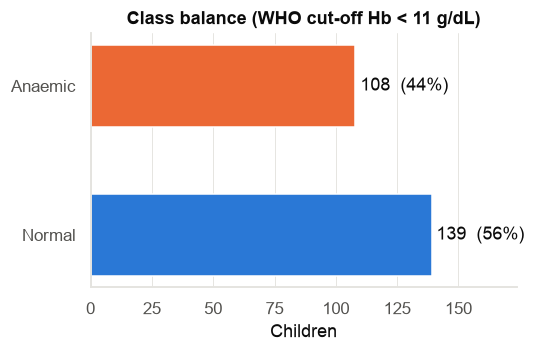

In [4]:
counts = df["Class"].value_counts().reindex(ORDER)
fig, ax = plt.subplots(figsize=(5, 3))
ax.barh(ORDER, counts.values, color=[PALETTE[c] for c in ORDER], height=0.55)
for i, v in enumerate(counts.values):
    ax.text(v + 2, i, f"{v}  ({100 * v / counts.sum():.0f}%)", va="center", color=INK)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Children")
ax.set_title("Class balance (WHO cut-off Hb < 11 g/dL)")
ax.grid(axis="y", visible=False)
save(fig, "02_class_balance")

**Findings — class balance.** 108 anaemic vs 139 normal (44% / 56%): mildly imbalanced, not severely. Stratified
folds keep this ratio per fold; SMOTE is optional and, if used, must sit inside the training pipeline. A trivial
"always Normal" classifier scores 56% accuracy, another reason never to headline accuracy.

## 3. Hb distribution with WHO cut-off and severity bands

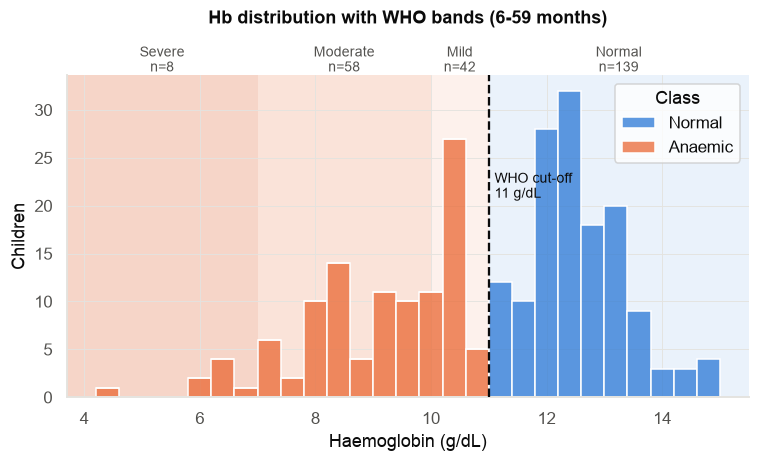

severity,normal,mild,moderate,severe
n,139,42,58,8


In [5]:
cut, mild_lo, severe_hi = _BANDS["child_6_59m"]
bands = [("Severe", df.hb.min() - 0.5, severe_hi, "#f6d5c8"), ("Moderate", severe_hi, mild_lo, "#fae3d9"),
         ("Mild", mild_lo, cut, "#fdf1ec"), ("Normal", cut, df.hb.max() + 0.5, "#eaf2fb")]
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, lo, hi, col in bands:
    ax.axvspan(lo, hi, color=col, zorder=0, lw=0)
    n = df.severity.eq(name.lower()).sum()
    ax.text((lo + hi) / 2, 1.0, f"{name}\nn={n}", transform=ax.get_xaxis_transform(), ha="center",
            va="bottom", fontsize=9, color=MUTED)
sns.histplot(df, x="hb", hue="Class", palette=PALETTE, hue_order=ORDER, binwidth=0.4, multiple="stack",
             edgecolor="white", linewidth=1, ax=ax, zorder=2)
ax.axvline(cut, color=INK, lw=1.5, ls="--", zorder=3)
ax.text(cut + 0.1, 0.62, f"WHO cut-off\n{cut:g} g/dL", transform=ax.get_xaxis_transform(), fontsize=9)
ax.set_xlim(df.hb.min() - 0.5, df.hb.max() + 0.5)
ax.set_xlabel("Haemoglobin (g/dL)")
ax.set_ylabel("Children")
ax.set_title("Hb distribution with WHO bands (6-59 months)", pad=34)
save(fig, "03_hb_distribution")
df.severity.value_counts().reindex(["normal", "mild", "moderate", "severe"]).to_frame("n").T

In [6]:
near = df.hb.between(cut - 0.5, cut + 0.5 - 1e-9)
print(f"Children within ±0.5 g/dL of the cut-off: {near.sum()} ({100 * near.mean():.0f}%)")

Children within ±0.5 g/dL of the cut-off: 31 (13%)


**Findings — Hb.** Hb spans 4.2–15.0 g/dL (median 11.7). Most anaemic children are moderate (58) or mild (42); only 8 are
severe, so a severity regressor will be poorly supported at the low end. 31 children (13%) sit within
±0.5 g/dL of the cut-off — measurement noise in Hb itself (typically ±0.5–1 g/dL for point-of-care meters) will
flip labels there, which caps achievable sensitivity/specificity for any colour-based screen.

## 4. MODEL_FEATURES: anaemic vs normal

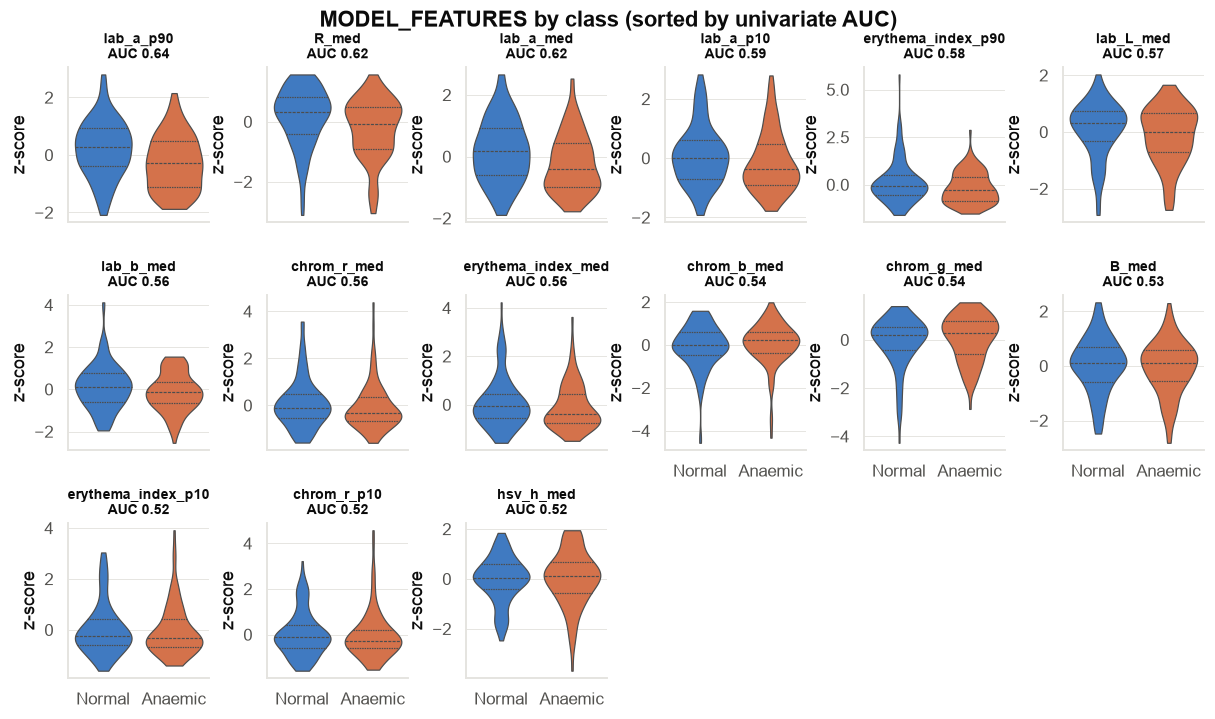

,AUC,MWU p
lab_a_p90,0.644,0.000
R_med,0.623,0.001
lab_a_med,0.621,0.001
lab_a_p10,0.587,0.019
erythema_index_p90,0.578,0.036
lab_L_med,0.569,0.062
lab_b_med,0.563,0.088
chrom_r_med,0.557,0.123
erythema_index_med,0.555,0.135
chrom_b_med,0.544,0.238


In [7]:
long = df.melt(id_vars="Class", value_vars=FEATS, var_name="feature")
long["z"] = long.groupby("feature")["value"].transform(lambda s: (s - s.mean()) / s.std())
stats = pd.DataFrame({
    "AUC": [auc(df.label, df[f]) for f in FEATS],
    "MWU p": [mannwhitneyu(df.loc[df.label == 1, f], df.loc[df.label == 0, f]).pvalue for f in FEATS],
}, index=FEATS)
order = stats.sort_values("AUC", ascending=False).index.tolist()

g = sns.catplot(long, x="Class", y="z", col="feature", col_order=order, col_wrap=6, kind="violin",
                hue="Class", palette=PALETTE, order=ORDER, hue_order=ORDER, inner="quart", cut=0,
                linewidth=0.8, height=2.2, aspect=0.85, sharey=False, legend=False)
for ax, f in zip(g.axes.flat, order):
    ax.set_title(f"{f}\nAUC {stats.loc[f, 'AUC']:.2f}", fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("z-score")
g.figure.suptitle("MODEL_FEATURES by class (sorted by univariate AUC)", y=1.02, fontweight="bold")
save(g.figure, "04_violins_model_features")
stats.loc[order].round(3)

**Findings — class separation.** Every single feature overlaps heavily between classes: the best univariate
AUCs (lab_a_p90, R_med, lab_a_med) are only ~0.62–0.64 and the rest are 0.52–0.59. Anaemic conjunctivae
are, on average, slightly *less red and darker*, in the expected direction, but no feature alone is a usable
screen. Gains must come from combining features — and a cross-validated AUC > ~0.85 from colour alone on this data should trigger a
leakage check.

## 5. Top features vs Hb (Spearman ρ)

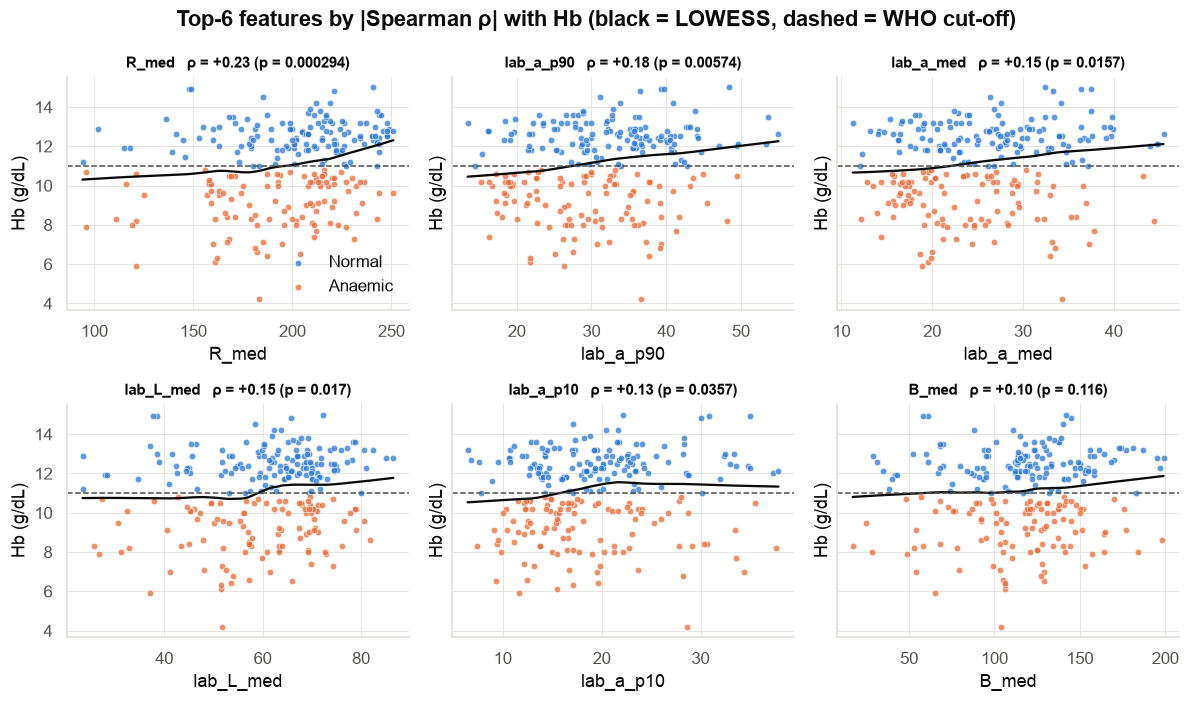

,rho,p,|rho|
feature,,,
R_med,0.2285,0.0003,0.2285
lab_a_p90,0.1753,0.0057,0.1753
lab_a_med,0.1536,0.0157,0.1536
lab_L_med,0.1517,0.0170,0.1517
lab_a_p10,0.1337,0.0357,0.1337
B_med,0.1003,0.1158,0.1003
lab_b_med,0.0930,0.1452,0.0930
erythema_index_p90,0.0591,0.3547,0.0591
chrom_r_med,0.0481,0.4519,0.0481


In [8]:
rho = pd.DataFrame([(f, *spearmanr(df[f], df.hb)) for f in FEATS], columns=["feature", "rho", "p"]).set_index("feature")
rho["|rho|"] = rho.rho.abs()
rho = rho.sort_values("|rho|", ascending=False)
top = rho.index[:6].tolist()

fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharey=True)
for ax, f in zip(axes.flat, top):
    for c in ORDER:
        s = df[df.Class == c]
        ax.scatter(s[f], s.hb, s=18, color=PALETTE[c], alpha=0.75, edgecolor="white", linewidth=0.5, label=c)
    sns.regplot(df, x=f, y="hb", scatter=False, lowess=True, color=INK, line_kws={"lw": 1.5}, ax=ax)
    ax.axhline(cut, color=MUTED, ls="--", lw=1)
    ax.set_title(f"{f}   ρ = {rho.loc[f, 'rho']:+.2f} (p = {rho.loc[f, 'p']:.3g})", fontsize=10)
    ax.set_ylabel("Hb (g/dL)")
axes[0, 0].legend(frameon=False, loc="lower right")
fig.suptitle("Top-6 features by |Spearman ρ| with Hb (black = LOWESS, dashed = WHO cut-off)", fontweight="bold")
fig.tight_layout()
save(fig, "05_top_features_vs_hb")
rho.round(4)

**Findings — continuous Hb.** The strongest monotonic associations are weak: |ρ| ≈ 0.23 for R_med,
≈ 0.15–0.18 for lab_a (median and p90) and lab_L. Chromaticity and ratio features (chrom_*,
erythema_index) have |ρ| < 0.06 — once overall brightness is divided out, almost no Hb signal remains. That is a
warning sign: much of the "signal" in R_med may be exposure/brightness, which is camera- and lighting-dependent
rather than physiological.

## 6. Feature redundancy and label-free pruning

The candidate set is the 24 raw colour features extracted per image. Pruning uses **only feature-feature Spearman correlations — no
labels, no Hb** — so it cannot leak outcome information into feature choice: drop `hsv_v_med` (identical to
`R_med / 255`), then for every pair with |ρ| > 0.95 drop the less interpretable member (`config.INTERPRETABILITY`).

Max |R_med/255 - hsv_v_med| = 1.11e-16  -> hsv_v_med dropped


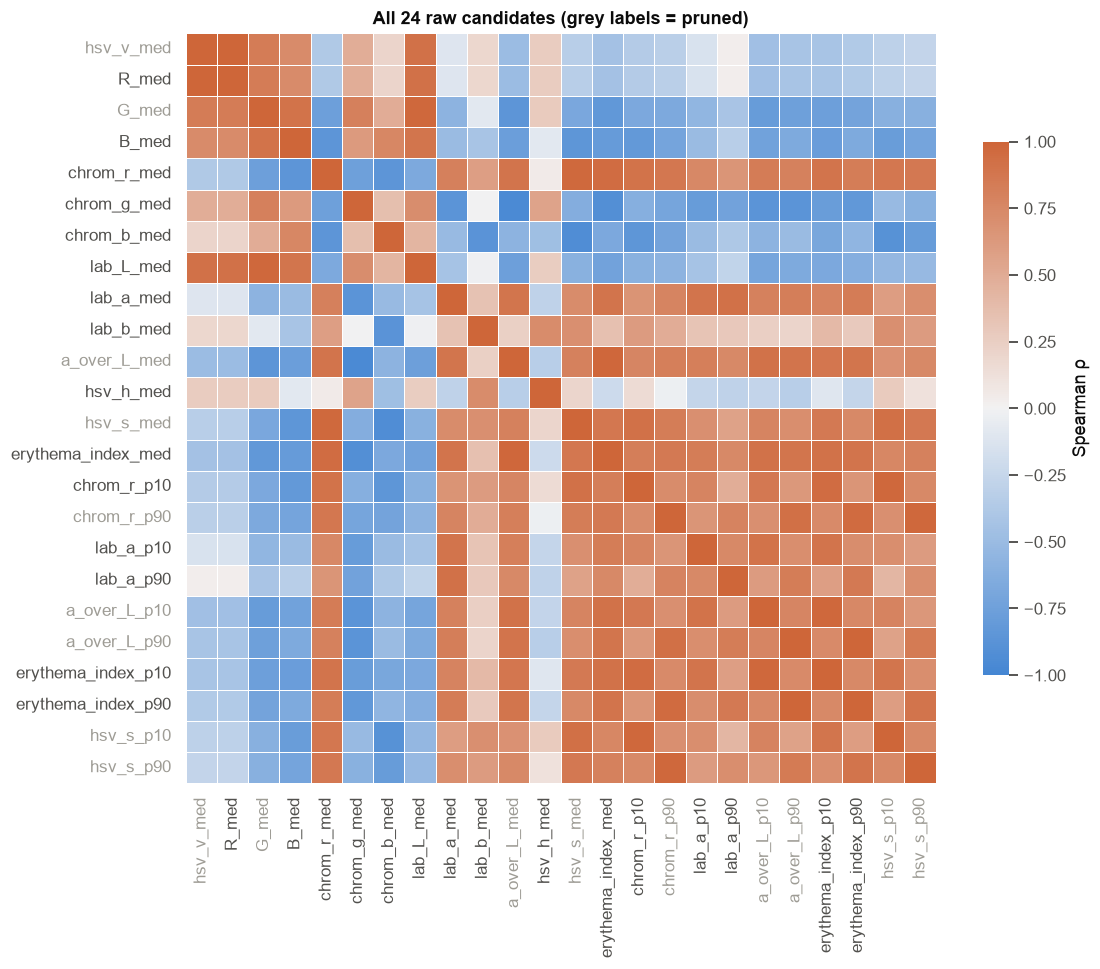

Candidate pairs with |rho| > 0.95: 10 of 276;  > 0.9: 26


,dropped,kept (more interpretable),|rho|
0,a_over_L_p90,erythema_index_p90,0.994
1,a_over_L_med,erythema_index_med,0.989
2,G_med,lab_L_med,0.983
3,hsv_s_p10,chrom_r_p10,0.981
4,hsv_s_p90,chrom_r_p90,0.978
5,a_over_L_p10,erythema_index_p10,0.977
6,hsv_s_med,chrom_r_med,0.974
7,chrom_r_p90,erythema_index_p90,0.958


In [9]:
print(f"Max |R_med/255 - hsv_v_med| = {(df.R_med / 255 - df.hsv_v_med).abs().max():.2e}  -> hsv_v_med dropped")
full = ["hsv_v_med"] + CANDS
corr = df[full].corr(method="spearman")
cmap = sns.diverging_palette(250, 25, s=80, l=55, as_cmap=True)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=cmap, center=0, vmin=-1, vmax=1, square=True, linewidths=0.4, linecolor="white",
            cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
for t in ax.get_xticklabels() + ax.get_yticklabels():
    if t.get_text() not in FEATS:
        t.set_color("#9e9c95")
ax.set_title("All 24 raw candidates (grey labels = pruned)")
save(fig, "06a_correlation_candidates")

pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().dropna()
print(f"Candidate pairs with |rho| > 0.95: {(pairs.abs() > 0.95).sum()} of {len(pairs)};  > 0.9: {(pairs.abs() > 0.9).sum()}")
keep, dropped = prune_redundant(df[CANDS], config.INTERPRETABILITY, config.REDUNDANCY_RHO)
assert keep == FEATS, "config.MODEL_FEATURES is out of date: run python -m scripts.prune_features"
pd.DataFrame(dropped, columns=["dropped", "kept (more interpretable)", "|rho|"]).round(3)

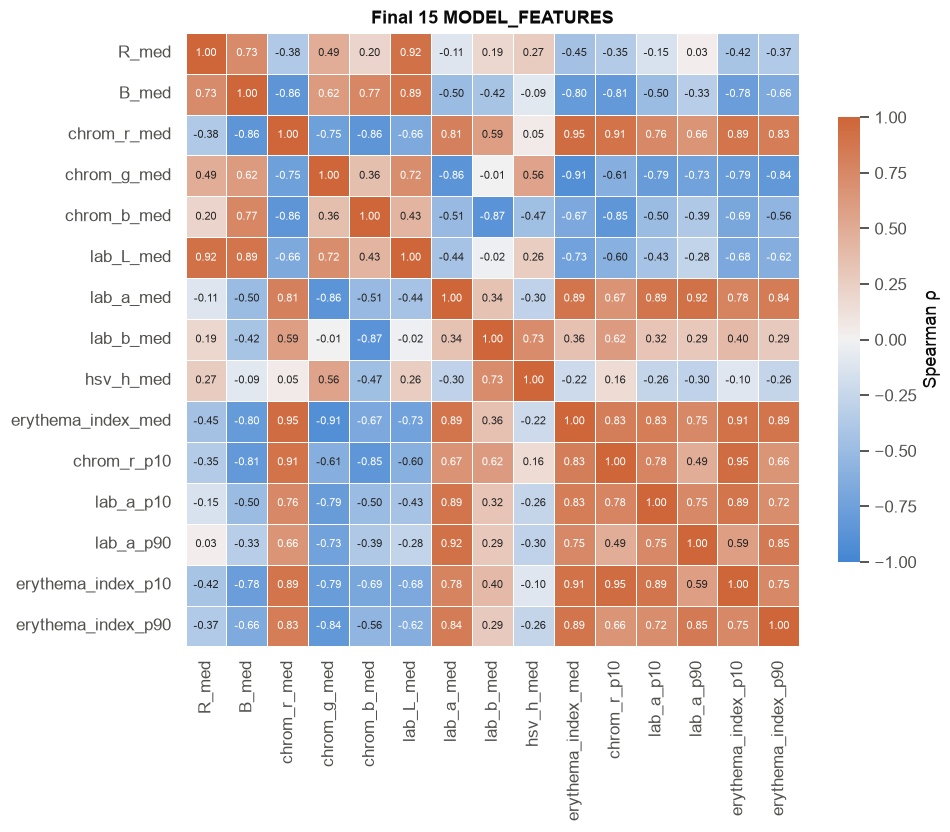

Max remaining |rho|: 0.947;  pairs > 0.8: 26 of 105
Max |chrom_r + chrom_g + chrom_b - 1| = 6.14e-03


In [10]:
corr15 = df[FEATS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr15, cmap=cmap, center=0, vmin=-1, vmax=1, square=True, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.4, linecolor="white", cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.set_title(f"Final {len(FEATS)} MODEL_FEATURES")
save(fig, "06b_correlation_model_features")

p15 = corr15.where(np.triu(np.ones(corr15.shape, bool), 1)).stack().dropna()
print(f"Max remaining |rho|: {p15.abs().max():.3f};  pairs > 0.8: {(p15.abs() > 0.8).sum()} of {len(p15)}")
print(f"Max |chrom_r + chrom_g + chrom_b - 1| = {(df.chrom_r_med + df.chrom_g_med + df.chrom_b_med - 1).abs().max():.2e}")

**Findings — redundancy.** `hsv_v_med` is exactly `R_med / 255` (V = max(R,G,B) and R is always
the max channel on conjunctiva). Of the remaining 23 candidates, 10 pairs exceed |ρ| = 0.95; the 8 drops above
resolve all of them (`a_over_L` ≈ `erythema_index`, `hsv_s` ≈ `chrom_r`, `G` ≈ `lab_L`), leaving **15 features**,
max remaining |ρ| = 0.947. Pruning is pairwise, so it does not catch multi-feature dependence:
`chrom_r + chrom_g + chrom_b ≈ 1` (medians, within 0.006), making the three chromaticity medians nearly collinear.
That is harmless for trees/KNN and for regularised logistic regression, but the from-scratch unregularised LogReg
should use L2 or drop one of them. Because pruning saw only X (never y or Hb), it is safe to fix it globally
rather than per fold.

**Naive Bayes note.** Gaussian NB assumes features are independent given the class. Even after pruning, the
remaining features are strongly correlated "redness" and "brightness" families, so NB will count the same evidence
several times and give over-confident, poorly calibrated probabilities (ranking/AUC can still be fine). Calibrate
the decision threshold inside each training fold and treat NB probabilities as scores, not risks.

## 7. Raw vs grey-world normalised features

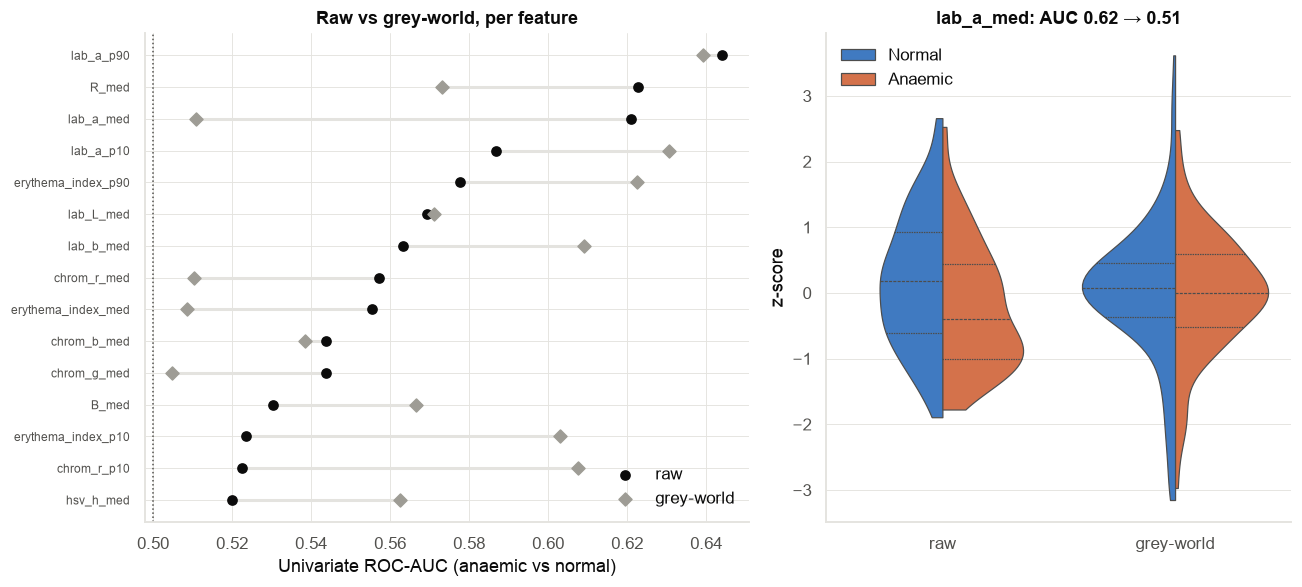

Median features: mean AUC raw 0.563 → grey-world 0.546
Percentile features: mean AUC raw 0.571 → grey-world 0.620


,raw AUC,grey-world AUC,raw ρ,grey-world ρ,Δ AUC,sign flip
lab_a_p90,0.644,0.639,0.175,0.137,-0.005,False
R_med,0.623,0.573,0.228,0.161,-0.050,False
lab_a_med,0.621,0.511,0.154,0.012,-0.110,False
lab_a_p10,0.587,0.630,0.134,-0.142,0.044,True
erythema_index_p90,0.578,0.623,0.059,0.099,0.045,False
lab_L_med,0.569,0.571,0.152,0.156,0.002,False
lab_b_med,0.563,0.609,0.093,0.145,0.046,False
chrom_r_med,0.557,0.510,0.048,-0.030,-0.047,True
erythema_index_med,0.555,0.509,0.044,-0.030,-0.047,True
chrom_b_med,0.544,0.539,-0.040,-0.018,-0.005,False


In [11]:
gw = pd.DataFrame({
    "raw AUC": [auc(df.label, df[f]) for f in FEATS],
    "grey-world AUC": [auc(df.label, df[f"gw_{f}"]) for f in FEATS],
    "raw ρ": [spearmanr(df[f], df.hb)[0] for f in FEATS],
    "grey-world ρ": [spearmanr(df[f"gw_{f}"], df.hb)[0] for f in FEATS],
}, index=FEATS)
gw["Δ AUC"] = gw["grey-world AUC"] - gw["raw AUC"]
gw["sign flip"] = np.sign(gw["raw ρ"]) != np.sign(gw["grey-world ρ"])
med = [f for f in FEATS if f.endswith("_med")]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
g2 = gw.loc[order]
y = np.arange(len(g2))
ax.hlines(y, g2["raw AUC"], g2["grey-world AUC"], color=GRID, lw=2)
ax.scatter(g2["raw AUC"], y, color=INK, s=36, label="raw", zorder=3)
ax.scatter(g2["grey-world AUC"], y, color="#9e9c95", s=36, marker="D", label="grey-world", zorder=3)
ax.set_yticks(y, g2.index, fontsize=8)
ax.invert_yaxis()
ax.axvline(0.5, color=MUTED, ls=":", lw=1)
ax.set_xlabel("Univariate ROC-AUC (anaemic vs normal)")
ax.set_title("Raw vs grey-world, per feature")
ax.legend(frameon=False, loc="lower right")

ax = axes[1]
f = "lab_a_med"
plot = pd.concat([df[[f, "Class"]].rename(columns={f: "value"}).assign(version="raw"),
                  df[[f"gw_{f}", "Class"]].rename(columns={f"gw_{f}": "value"}).assign(version="grey-world")])
plot["z"] = plot.groupby("version")["value"].transform(lambda s: (s - s.mean()) / s.std())
sns.violinplot(plot, x="version", y="z", hue="Class", hue_order=ORDER, palette=PALETTE, split=True,
               inner="quart", cut=0, linewidth=0.8, ax=ax)
ax.set_title(f"{f}: AUC {gw.loc[f, 'raw AUC']:.2f} → {gw.loc[f, 'grey-world AUC']:.2f}")
ax.set_xlabel("")
ax.set_ylabel("z-score")
ax.legend(frameon=False, title=None)
fig.tight_layout()
save(fig, "07_raw_vs_greyworld")

print(f"Median features: mean AUC raw {gw.loc[med, 'raw AUC'].mean():.3f} → grey-world {gw.loc[med, 'grey-world AUC'].mean():.3f}")
pct = [f for f in FEATS if f not in med]
print(f"Percentile features: mean AUC raw {gw.loc[pct, 'raw AUC'].mean():.3f} → grey-world {gw.loc[pct, 'grey-world AUC'].mean():.3f}")
gw.loc[order].round(3)

In [12]:
quality = ["pixel_eq_frac", "lap_var", "tissue_px"]
clean = df[~(df.flag_blur | df.flag_upscaled)]
rows = {}
for f in ["lab_a_med", "chrom_r_p10", "erythema_index_p10", "lab_a_p10"]:
    for v, p in [("raw", ""), ("grey-world", "gw_")]:
        r = {f"ρ vs {q}": spearmanr(df[p + f], df[q])[0] for q in quality}
        r["AUC"] = auc(df.label, df[p + f])
        r["AUC (unflagged only)"] = auc(clean.label, clean[p + f])
        rows[(f, v)] = r
pd.DataFrame(rows).T.round(3)

ρ vs pixel_eq_frac  ρ vs lap_var  \
lab_a_med          raw                     -0.271         0.321   
                   grey-world              -0.128         0.114   
chrom_r_p10        raw                      0.006         0.046   
                   grey-world               0.419        -0.323   
erythema_index_p10 raw                     -0.021         0.099   
                   grey-world               0.410        -0.355   
lab_a_p10          raw                     -0.073         0.172   
                   grey-world               0.428        -0.405   

                               ρ vs tissue_px    AUC  AUC (unflagged only)  
lab_a_med          raw                  0.182  0.621                 0.604  
                   grey-world          -0.127  0.511                 0.523  
chrom_r_p10        raw                  0.113  0.522                 0.527  
                   grey-world          -0.155  0.607                 0.597  
erythema_index_p10 raw                  0.131  0.524                 0.524  
                   grey-world          -0.173  0.603                 0.591  
lab_a_p10          raw                  0.199  0.587                 0.572  
                   grey-world          -0.145  0.630                 0.616

**Findings — grey-world.** Grey-world (gains computed on the tissue mask) forces each image's mean tissue colour
to grey, so it **erases the absolute redness signal**: lab_a_med drops from AUC 0.62 to ~0.51 (chance), R_med and
erythema_index_med also fall, and several Hb correlations change sign. The physiologically meaningful quantity —
*how red the conjunctiva is* — is exactly what grey-world normalises away, because the tissue is the only thing in
the frame.

Caveat, stated honestly: grey-world does **not** weaken everything. The *percentile* features gain AUC on average
(0.57 → 0.62 across the MODEL_FEATURES percentiles), with several Hb correlations flipping sign. After grey-world, p10 becomes "how far the darkest tissue
lies below the image mean", i.e. within-image contrast — and the table above shows these grey-world p10 features
correlate at |ρ| ≈ 0.3–0.4 with sharpness (lap_var) and upscaling (pixel_eq_frac), where the raw versions
correlated ≈ 0. The gain mostly persists after dropping flagged images, because the quality link is continuous, not
just the flagged tail. So the extra separation is largely a capture-quality proxy (see Section 8), not pallor.
Conclusion: keep raw features for CP-AnemiC; grey-world remains only as a fallback for full-scene photos where a
neutral background exists, and sclera normalisation is the preferred route for Eyes-defy-anemia.

## 8. Shortcut confounders: glare, tissue area, blur, upscaling

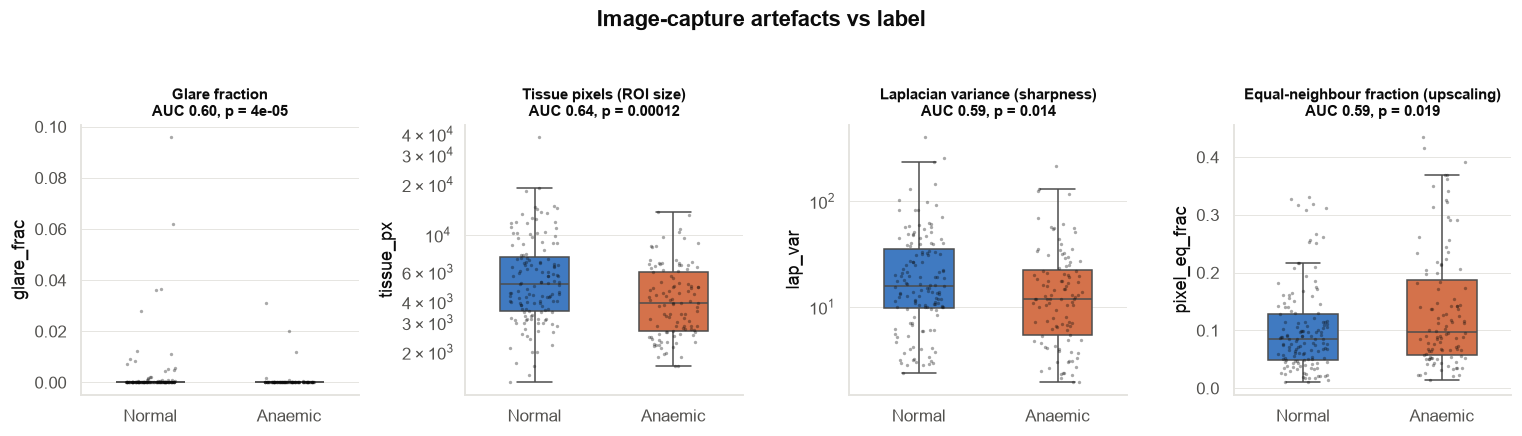

,% blurry,% upscaled,% high glare
Class,,,
Normal,4.3,4.3,1.4
Anaemic,9.3,10.2,0.0


In [13]:
conf = {"glare_frac": "Glare fraction", "tissue_px": "Tissue pixels (ROI size)",
        "lap_var": "Laplacian variance (sharpness)", "pixel_eq_frac": "Equal-neighbour fraction (upscaling)"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (c, title) in zip(axes, conf.items()):
    log_scale = c in ("tissue_px", "lap_var")
    sns.boxplot(df, x="Class", y=c, hue="Class", order=ORDER, hue_order=ORDER, palette=PALETTE, width=0.5,
                fliersize=0, linewidth=1, ax=ax, log_scale=log_scale, legend=False)
    sns.stripplot(df, x="Class", y=c, order=ORDER, color=INK, size=2.2, alpha=0.35, jitter=0.18, ax=ax)
    p = mannwhitneyu(df.loc[df.label == 1, c], df.loc[df.label == 0, c]).pvalue
    ax.set_title(f"{title}\nAUC {auc(df.label, df[c]):.2f}, p = {p:.2g}", fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Image-capture artefacts vs label", fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "08_shortcut_confounders")

rates = df.groupby("Class")[["flag_blur", "flag_upscaled", "flag_high_glare"]].mean().reindex(ORDER).mul(100).round(1)
rates.columns = ["% blurry", "% upscaled", "% high glare"]
rates

In [14]:
cmp = pd.DataFrame({"AUC vs label": [auc(df.label, df[c]) for c in conf],
                    "ρ vs Hb": [spearmanr(df[c], df.hb)[0] for c in conf]}, index=list(conf))
cmp.loc["best colour feature (lab_a_p90)"] = [stats.loc["lab_a_p90", "AUC"], rho.loc["lab_a_p90", "rho"]]
cmp.round(3)

,AUC vs label,ρ vs Hb
glare_frac,0.600,0.224
tissue_px,0.643,0.197
lap_var,0.592,0.169
pixel_eq_frac,0.587,-0.095
best colour feature (lab_a_p90),0.644,0.175


**Findings — shortcuts.** Capture artefacts are associated with the label about as strongly as the best colour
feature: tissue_px alone reaches AUC ≈ 0.64 and glare_frac ≈ 0.60. Anaemic images are smaller crops, blurrier, carry
*less* glare (normal images are the glare-heavy ones), and are about twice as likely to be flagged blurry
(9.3% vs 4.3%) or upscaled (10.2% vs 4.3%). These are properties of *how the photo was
taken/cropped* in this particular data collection (likely batch or device effects), not of haemoglobin. A model
fed these would learn the collection protocol, inflate CV scores, and fail on Eyes-defy-anemia or in the app,
where crops are user-drawn. Hence `EXCLUDED_FEATURES = ["glare_frac", "tissue_px"]`, and quality metrics are used
only as flags. They also partly contaminate colour features (e.g. percentile spread), so a sensitivity analysis
excluding flagged images is worthwhile in the modelling notebook.

## 9. PCA projection (2-D)

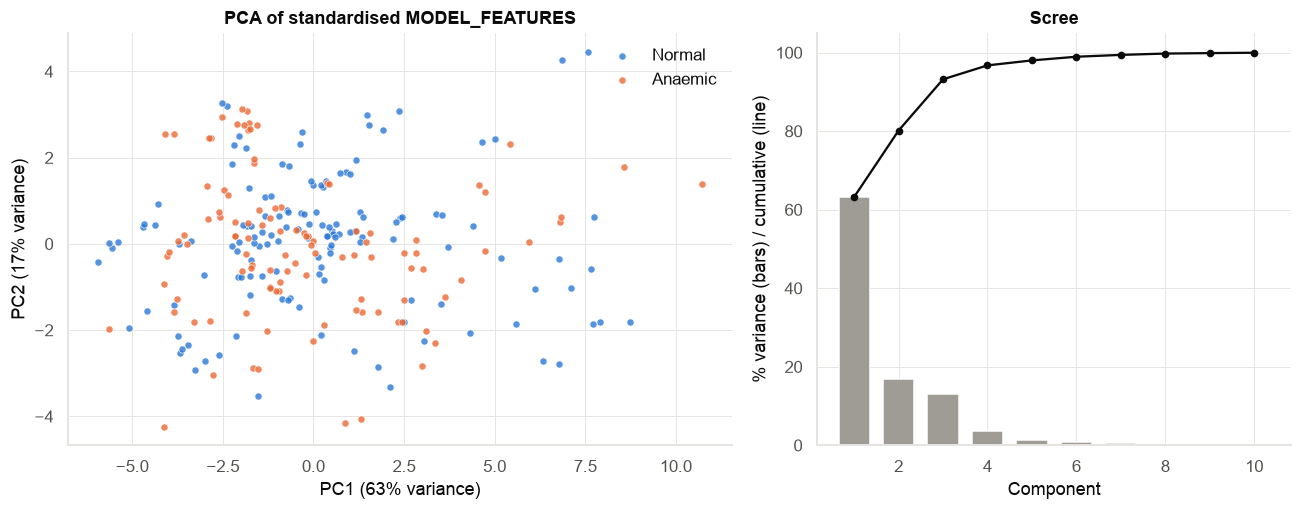

Components for 90% / 95% variance: 3 / 4
AUC of each PC vs label: {'PC1': 0.552, 'PC2': 0.526, 'PC3': 0.67, 'PC4': 0.552}


,PC1,PC2
erythema_index_med,0.319,-0.057
chrom_r_med,0.314,0.119
erythema_index_p10,0.307,-0.027
chrom_r_p10,0.300,0.131
B_med,-0.287,-0.089
chrom_g_med,-0.287,0.269
erythema_index_p90,0.276,-0.085
lab_a_med,0.264,-0.063


In [15]:
Z = StandardScaler().fit_transform(df[FEATS])
pca = PCA(n_components=min(10, len(FEATS)), random_state=config.SEED).fit(Z)
pcs = pca.transform(Z)
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
for c in ORDER:
    m = df.Class == c
    ax.scatter(pcs[m, 0], pcs[m, 1], s=22, color=PALETTE[c], alpha=0.8, edgecolor="white", linewidth=0.5, label=c)
ax.set_xlabel(f"PC1 ({100 * ev[0]:.0f}% variance)")
ax.set_ylabel(f"PC2 ({100 * ev[1]:.0f}% variance)")
ax.set_title("PCA of standardised MODEL_FEATURES")
ax.legend(frameon=False)

ax = axes[1]
ax.bar(range(1, len(ev) + 1), ev * 100, color="#9e9c95", width=0.7)
ax.plot(range(1, len(ev) + 1), np.cumsum(ev) * 100, color=INK, marker="o", ms=4, lw=1.5)
ax.set_xlabel("Component")
ax.set_ylabel("% variance (bars) / cumulative (line)")
ax.set_title("Scree")
fig.tight_layout()
save(fig, "09_pca")

print(f"Components for 90% / 95% variance: {np.searchsorted(np.cumsum(ev), 0.90) + 1} / {np.searchsorted(np.cumsum(ev), 0.95) + 1}")
print("AUC of each PC vs label:", {f"PC{i + 1}": round(auc(df.label, pcs[:, i]), 3) for i in range(4)})
pd.DataFrame(pca.components_[:2].T, index=FEATS, columns=["PC1", "PC2"]).round(3).sort_values("PC1", key=abs, ascending=False).head(8)

**Findings — PCA.** Even after pruning, three components explain 90% of the variance in the 15 features (4 for 95%):
they are still a few correlated families. The classes overlap almost completely in the PC1–PC2 plane: PC1 (overall redness /
chromaticity) has AUC only 0.55, PC2 0.53, and the most label-related component is PC3 (AUC 0.67). The dominant directions of
colour variation (largely lighting and camera) are not the anaemia direction, so unsupervised reduction to 2 PCs
would throw the signal away. This
is consistent with modest univariate AUCs and sets expectations for the classifiers — a realistic CV ROC-AUC is
probably in the 0.6–0.75 range. (PCA was fitted on all rows here for visualisation only; inside models it must be
fitted per training fold.)

## Key findings

1. **Signal is real but weak.** Anaemic conjunctivae are slightly less red / darker, but the best single feature
   reaches only AUC ≈ 0.64 and |ρ| with Hb ≈ 0.23. Multivariate models are needed, and any CV AUC > ~0.85 should be
   treated as suspected leakage.
2. **Heavy redundancy, pruned without labels.** `hsv_v_med` is an exact copy of `R_med / 255`, and 10 candidate
   pairs have |ρ| > 0.95. Label-free pruning takes 24 candidates → 15 MODEL_FEATURES, yet 26 remaining pairs are
   still > 0.8 and 3 PCs hold 90% of the variance — expect over-confident Naive Bayes probabilities.
3. **Grey-world removes the absolute pallor signal** on this tissue-only dataset (lab_a_med AUC 0.62 → 0.51);
   its gains on percentile features come with a new |ρ| ≈ 0.4 dependence on sharpness/upscaling. Use raw features.
4. **Capture artefacts are shortcuts.** Tissue area (AUC 0.64) and glare (0.60) predict the label as well
   as the best colour feature (0.64), and blur/upscaling flags are ~2× more common in anaemic images — exclude them as inputs and run a sensitivity
   check on unflagged images.
5. **Label noise near the cut-off and few severe cases.** 31 children (13%) are within ±0.5 g/dL of 11 g/dL and only
   8 are severe — limits achievable sensitivity/specificity and makes severity regression weakly supported.